---
## 1. Import Necessary Libraries

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Set consistent visual style and random seed for reproducibility
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

---
## 2. Data Import & Initial Inspection (EDA)

In [5]:
# Load dataset
import os, pathlib
notebook_dir = pathlib.Path(globals().get('__vsc_ipynb_file__', os.path.abspath('__file__'))).parent
df = pd.read_csv(notebook_dir / 'student_grades.csv')

# Define the 8 core subject columns (excluding student_id)
SUBJECTS = ["math", "science", "cs", "band", "english", "history", "spanish", "physed"]

print(f"Dataset Shape: {df.shape[0]} students x {df.shape[1]} columns")
print("\n--- Data Info ---")
df.info()

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

print(f"\nDuplicate Rows: {df.duplicated().sum()}")
df.head()


Dataset Shape: 100 students x 9 columns

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   student_id  100 non-null    int64
 1   math        100 non-null    int64
 2   science     100 non-null    int64
 3   cs          100 non-null    int64
 4   band        100 non-null    int64
 5   english     100 non-null    int64
 6   history     100 non-null    int64
 7   spanish     100 non-null    int64
 8   physed      100 non-null    int64
dtypes: int64(9)
memory usage: 7.2 KB

--- Missing Values per Column ---
student_id    0
math          0
science       0
cs            0
band          0
english       0
history       0
spanish       0
physed        0
dtype: int64

Duplicate Rows: 0


,student_id,math,science,cs,band,english,history,spanish,physed
0,1,46,48,50,74,34,44,39,73
1,2,66,65,65,66,74,80,75,63
2,3,55,53,50,76,71,72,76,71
3,4,53,57,53,80,77,77,85,82
4,5,55,62,58,67,82,77,78,60


In [6]:
# Summary statistics across all 8 subjects
summary_stats = df[SUBJECTS].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)
print("--- Subject Grade Summary Statistics ---")
summary_stats

--- Subject Grade Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
math,100.0,53.05,13.91,21.0,45.00,51.5,58.00,93.0
science,100.0,53.22,14.00,22.0,44.75,52.0,59.25,94.0
cs,100.0,52.75,13.46,28.0,44.00,50.0,58.25,92.0
band,100.0,70.04,6.28,60.0,64.00,71.0,75.00,80.0
english,100.0,60.97,17.31,30.0,48.00,60.5,74.00,90.0
history,100.0,63.60,17.48,28.0,50.75,65.0,78.00,98.0
spanish,100.0,65.56,18.41,31.0,49.50,68.5,79.00,99.0
physed,100.0,67.61,8.07,51.0,62.75,67.0,74.25,84.0


### 2.1 Distribution & Correlation Analysis

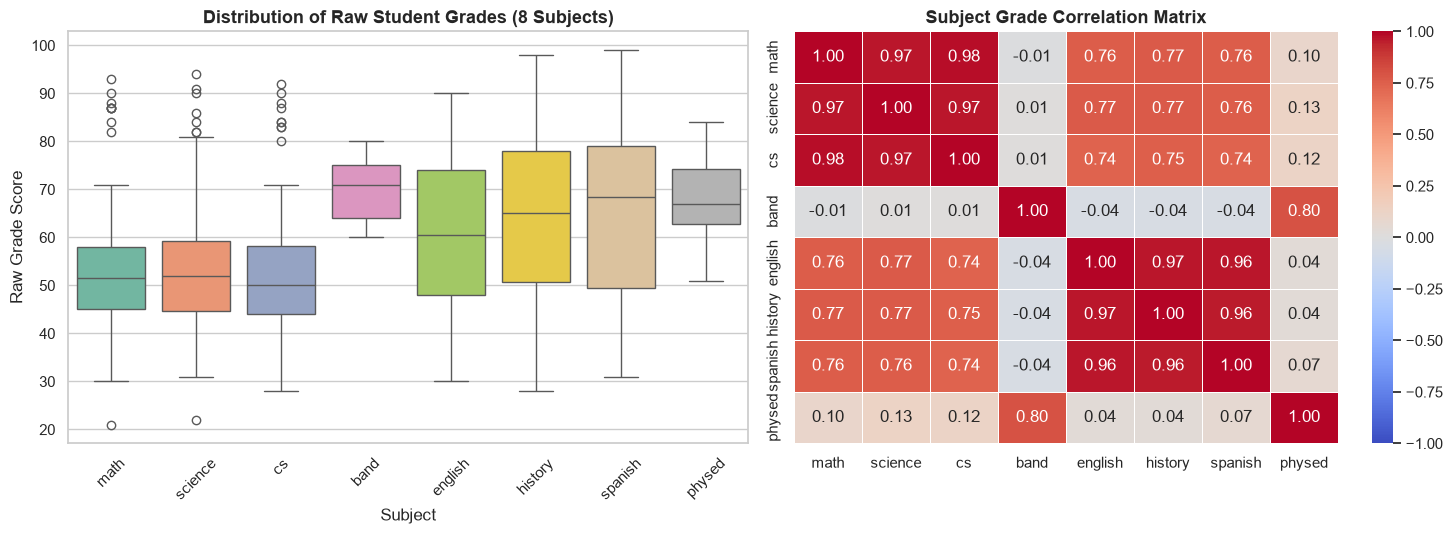

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: Subject Grade Distributions (Boxplot)
sns.boxplot(data=df[SUBJECTS], palette="Set2", ax=axes[0])
axes[0].set_title("Distribution of Raw Student Grades (8 Subjects)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Subject")
axes[0].set_ylabel("Raw Grade Score")
axes[0].tick_params(axis="x", rotation=45)

# Right: Pairwise Correlation Heatmap
corr_matrix = df[SUBJECTS].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[1]
)
axes[1].set_title("Subject Grade Correlation Matrix", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

---
## 3. Data Preprocessing & Feature Standardization


In [8]:
# Isolate student_id from numeric feature matrix
student_ids = df["student_id"]
X_raw = df[SUBJECTS].copy()

# Apply Z-score standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
df_scaled = pd.DataFrame(X_scaled, columns=SUBJECTS)

# Verify before vs. after mean and standard deviation
verification_df = pd.DataFrame({
    "Original Mean": X_raw.mean().round(2),
    "Original Std": X_raw.std(ddof=0).round(2),
    "Scaled Mean": df_scaled.mean().round(4),
    "Scaled Std": df_scaled.std(ddof=0).round(4)
})
print("--- Standardization Verification ---")
verification_df

--- Standardization Verification ---


,Original Mean,Original Std,Scaled Mean,Scaled Std
math,53.05,13.84,0.0,1.0
science,53.22,13.93,0.0,1.0
cs,52.75,13.40,-0.0,1.0
band,70.04,6.25,-0.0,1.0
english,60.97,17.22,0.0,1.0
history,63.60,17.39,-0.0,1.0
spanish,65.56,18.31,-0.0,1.0
physed,67.61,8.03,0.0,1.0


---
## 4. Linear Dimensionality Reduction — Full PCA


In [9]:
# Fit full PCA across all 8 dimensions
pca_full = PCA(random_state=RANDOM_STATE)
X_pca_full = pca_full.fit_transform(X_scaled)

explained_var_pct = pca_full.explained_variance_ratio_ * 100
cumulative_var_pct = np.cumsum(explained_var_pct)

variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(SUBJECTS) + 1)],
    "Eigenvalue": pca_full.explained_variance_.round(3),
    "Variance Explained (%)": explained_var_pct.round(2),
    "Cumulative Variance (%)": cumulative_var_pct.round(2)
})
print("--- PCA Explained Variance Table ---")
variance_table

--- PCA Explained Variance Table ---


,Component,Eigenvalue,Variance Explained (%),Cumulative Variance (%)
0,PC1,5.269,65.20,65.20
1,PC2,1.826,22.59,87.79
2,PC3,0.664,8.21,96.00
3,PC4,0.195,2.42,98.42
4,PC5,0.041,0.51,98.93
5,PC6,0.040,0.49,99.42
6,PC7,0.027,0.33,99.75
7,PC8,0.020,0.25,100.00


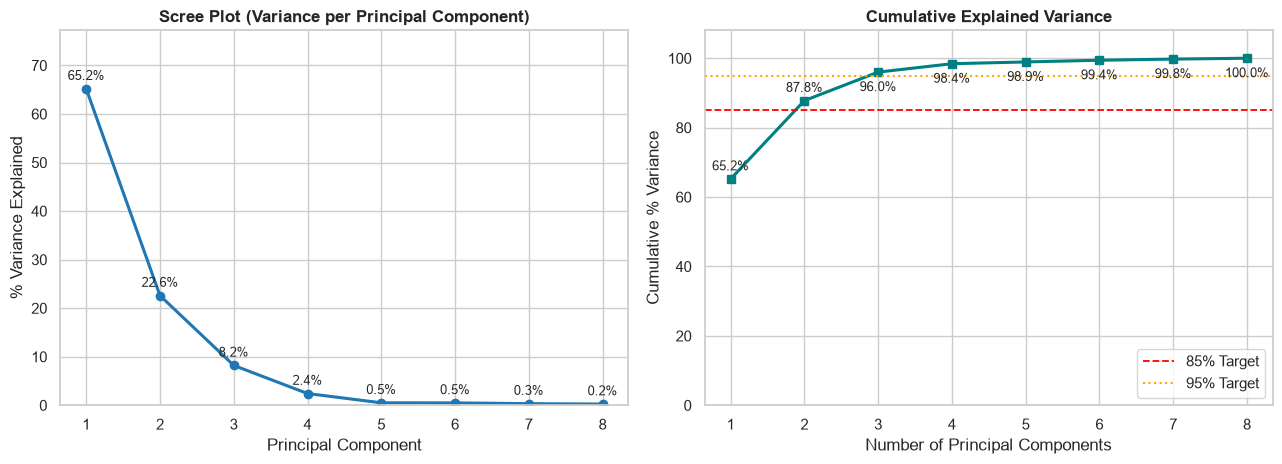

In [10]:
# Scree Plot & Cumulative Explained Variance Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
components_range = range(1, len(SUBJECTS) + 1)

# Scree Plot
axes[0].plot(components_range, explained_var_pct, marker="o", linewidth=2.2, color="#1f77b4")
for i, val in enumerate(explained_var_pct):
    axes[0].text(i + 1, val + 1.8, f"{val:.1f}%", ha="center", fontsize=9)
axes[0].set_title("Scree Plot (Variance per Principal Component)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("% Variance Explained")
axes[0].set_xticks(components_range)
axes[0].set_ylim(0, max(explained_var_pct) + 12)

# Cumulative Explained Variance
axes[1].plot(components_range, cumulative_var_pct, marker="s", linewidth=2.2, color="teal")
axes[1].axhline(85, color="red", linestyle="--", linewidth=1.3, label="85% Target")
axes[1].axhline(95, color="orange", linestyle=":", linewidth=1.5, label="95% Target")
for i, val in enumerate(cumulative_var_pct):
    offset = -5.5 if val > 92 else 2.5
    axes[1].text(i + 1, val + offset, f"{val:.1f}%", ha="center", fontsize=9)
axes[1].set_title("Cumulative Explained Variance", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative % Variance")
axes[1].set_xticks(components_range)
axes[1].set_ylim(0, 108)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Key Finding from Variance Analysis
---
## 5. Latent Feature Interpretation & Component Loadings

--- PCA Component Loadings (PC1 - PC3) ---
         PC1 (Core Aptitude)  PC2 (Electives)  PC3 (STEM vs Humanities)
math                   0.411            0.010                     0.397
science                0.411            0.029                     0.382
cs                     0.405            0.027                     0.437
band                  -0.002            0.706                    -0.090
english                0.407           -0.052                    -0.412
history                0.408           -0.052                    -0.397
spanish                0.406           -0.040                    -0.411
physed                 0.047            0.702                    -0.031


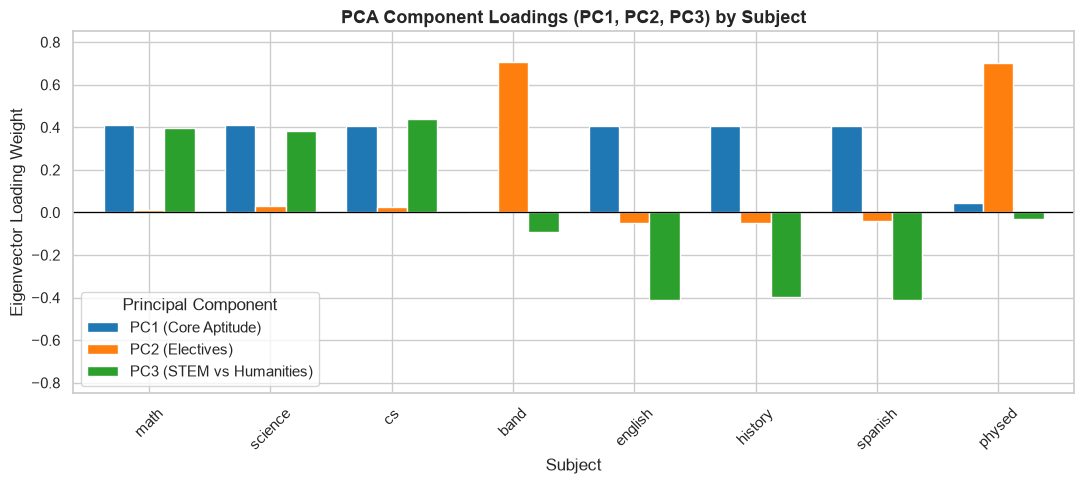

In [11]:
# Extract loadings for the top 3 principal components
loadings_df = pd.DataFrame(
    pca_full.components_[:3].T,
    columns=["PC1 (Core Aptitude)", "PC2 (Electives)", "PC3 (STEM vs Humanities)"],
    index=SUBJECTS
)
print("--- PCA Component Loadings (PC1 - PC3) ---")
print(loadings_df.round(3))

# Plot Component Loadings Bar Chart
ax = loadings_df.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75,
    color=["#1f77b4", "#ff7f0e", "#2ca02c"]
)
plt.axhline(0, color="black", linewidth=0.9)
plt.title("PCA Component Loadings (PC1, PC2, PC3) by Subject", fontsize=13, fontweight="bold")
plt.xlabel("Subject")
plt.ylabel("Eigenvector Loading Weight")
plt.xticks(rotation=45)
plt.ylim(-0.85, 0.85)
plt.legend(title="Principal Component")
plt.tight_layout()
plt.show()

### Semantic Interpretation of Latent Axes
---
## 6. 2D & 3D PCA Projections with K-Means Student Profiles

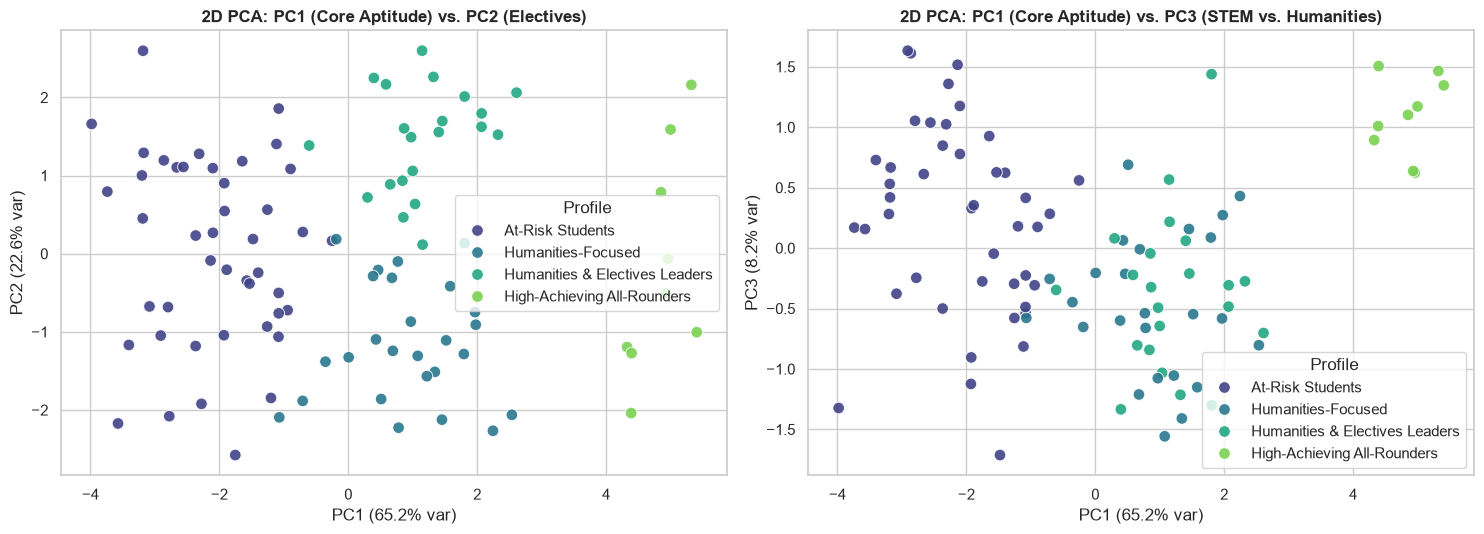

In [12]:
# Assign 4 clusters using K-Means on the standardized feature space
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Map numeric cluster IDs to human-readable academic profiles (verified in Section 7)
PROFILE_MAP = {
    0: "Humanities-Focused",
    1: "Humanities & Electives Leaders",
    2: "At-Risk Students",
    3: "High-Achieving All-Rounders"
}
df["Profile"] = df["Cluster"].map(PROFILE_MAP)

# Attach top 3 PC coordinates to DataFrame
df["PC1"] = X_pca_full[:, 0]
df["PC2"] = X_pca_full[:, 1]
df["PC3"] = X_pca_full[:, 2]

# 2D PCA Scatter Plots: (PC1 vs PC2) and (PC1 vs PC3)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(
    data=df, x="PC1", y="PC2", hue="Profile",
    palette="viridis", s=70, alpha=0.9, ax=axes[0]
)
axes[0].set_title("2D PCA: PC1 (Core Aptitude) vs. PC2 (Electives)", fontsize=12, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({explained_var_pct[0]:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({explained_var_pct[1]:.1f}% var)")

sns.scatterplot(
    data=df, x="PC1", y="PC3", hue="Profile",
    palette="viridis", s=70, alpha=0.9, ax=axes[1]
)
axes[1].set_title("2D PCA: PC1 (Core Aptitude) vs. PC3 (STEM vs. Humanities)", fontsize=12, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({explained_var_pct[0]:.1f}% var)")
axes[1].set_ylabel(f"PC3 ({explained_var_pct[2]:.1f}% var)")

plt.tight_layout()
plt.show()

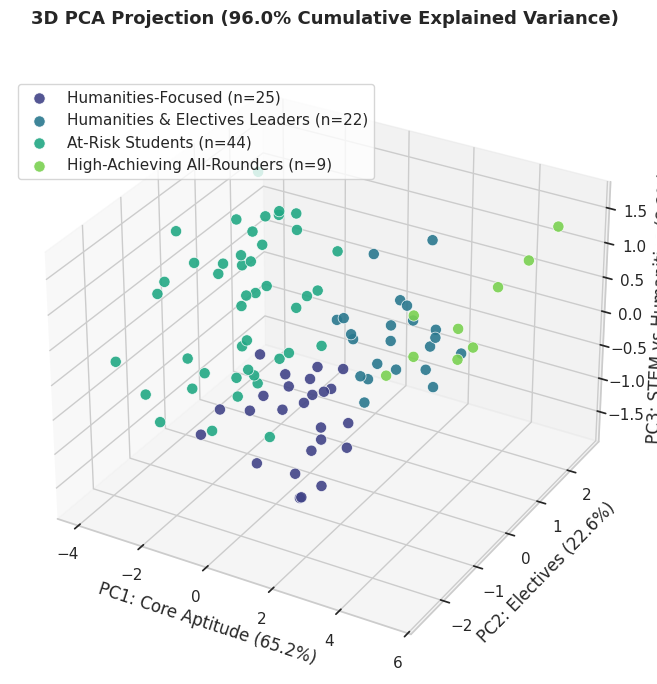

In [10]:
# Static 3D PCA Scatter Plot (Matplotlib — captures 96.0% of total variance)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

palette = sns.color_palette("viridis", n_colors=4)
for cluster_id, profile_name in PROFILE_MAP.items():
    subset = df[df["Cluster"] == cluster_id]
    ax.scatter(
        subset["PC1"], subset["PC2"], subset["PC3"],
        label=f"{profile_name} (n={len(subset)})",
        color=palette[cluster_id],
        s=65, alpha=0.9, edgecolors="w", linewidth=0.5
    )

ax.set_title("3D PCA Projection (96.0% Cumulative Explained Variance)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel(f"PC1: Core Aptitude ({explained_var_pct[0]:.1f}%)")
ax.set_ylabel(f"PC2: Electives ({explained_var_pct[1]:.1f}%)")
ax.set_zlabel(f"PC3: STEM vs Humanities ({explained_var_pct[2]:.1f}%)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.95))
plt.tight_layout()
plt.show()

In [13]:
# Interactive 3D PCA Scatter Plot (Plotly — hover over points to inspect individual students)
fig_3d = px.scatter_3d(
    df,
    x="PC1", y="PC2", z="PC3",
    color="Profile",
    hover_data=["student_id"] + SUBJECTS,
    title="Interactive 3D PCA Student Academic Profiles (96.0% Variance)",
    labels={
        "PC1": f"PC1: Core Aptitude ({explained_var_pct[0]:.1f}%)",
        "PC2": f"PC2: Electives ({explained_var_pct[1]:.1f}%)",
        "PC3": f"PC3: STEM vs Humanities ({explained_var_pct[2]:.1f}%)"
    }
)
fig_3d.update_traces(marker=dict(size=6, line=dict(width=0.5, color="white")))
fig_3d.show()

---
## 7. Cluster Profiling & Business Recommendations
We aggregate the raw subject grades by cluster to validate our profile labels and translate findings into actionable advising strategies.

--- Academic Profile Summary Table ---
                                math  science    cs  band  english  history  \
Profile                                                                       
At-Risk Students                42.5     42.4  42.9  70.0     45.0     47.0   
High-Achieving All-Rounders     87.2     85.4  85.7  68.3     87.0     90.6   
Humanities & Electives Leaders  58.1     58.5  57.4  76.4     70.5     72.9   
Humanities-Focused              54.8     56.0  54.2  65.2     71.4     75.0   

                                spanish  physed  Count  STEM_Avg  Hum_Avg  \
Profile                                                                     
At-Risk Students                   48.2    66.8     44      42.6     46.7   
High-Achieving All-Rounders        94.0    68.6      9      86.1     90.5   
Humanities & Electives Leaders     76.8    76.2     22      58.0     73.4   
Humanities-Focused                 75.9    61.1     25      55.0     74.1   

                       

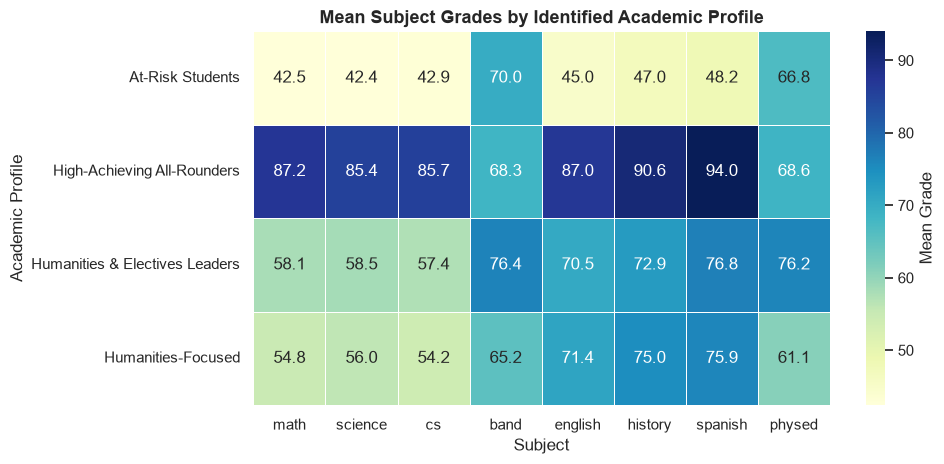

In [14]:
# Compute mean grades and domain averages per profile
profile_summary = df.groupby("Profile")[SUBJECTS].mean().round(1)
profile_summary["Count"] = df.groupby("Profile")["student_id"].count()
profile_summary["STEM_Avg"] = df.groupby("Profile")[["math", "science", "cs"]].mean().mean(axis=1).round(1)
profile_summary["Hum_Avg"] = df.groupby("Profile")[["english", "history", "spanish"]].mean().mean(axis=1).round(1)
profile_summary["Elec_Avg"] = df.groupby("Profile")[["band", "physed"]].mean().mean(axis=1).round(1)
profile_summary["Overall_Avg"] = df.groupby("Profile")[SUBJECTS].mean().mean(axis=1).round(1)

print("--- Academic Profile Summary Table ---")
print(profile_summary)

# Heatmap of average subject grades by profile
plt.figure(figsize=(10, 4.8))
sns.heatmap(
    profile_summary[SUBJECTS],
    annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5,
    cbar_kws={"label": "Mean Grade"}
)
plt.title("Mean Subject Grades by Identified Academic Profile", fontsize=13, fontweight="bold")
plt.xlabel("Subject")
plt.ylabel("Academic Profile")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()